In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm  # Progress bar for loading files

In [2]:
# Ensure Jupyter displays plots inline
%matplotlib inline  

In [3]:
# Define the path to the dataset directory
split_dir = "satellite_data"
splits = ["train", "val", "fix_val"]

# Define the bins and labels
bins = np.arange(0, 70, 5)  # Creates bins [0, 5, 10, ..., 65]
labels = [f"{bins[i]}-{bins[i+1]}" for i in range(len(bins)-1)]
labels.append(">65")  # Extra label for values above 65

# Define column containing the .npz file paths
path_column = "path"  # Adjust if needed
array_key = "data"  # Adjust based on your .npz structure

# Initialize plot variables
plt_train, plt_val, plt_fixval = None, None, None


Processing train:   0%|          | 0/9407 [00:00<?, ?file/s]

Processing train: 100%|██████████| 9407/9407 [28:44<00:00,  5.45file/s]  
/tmp/ipykernel_408205/3549145240.py:55: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=45)


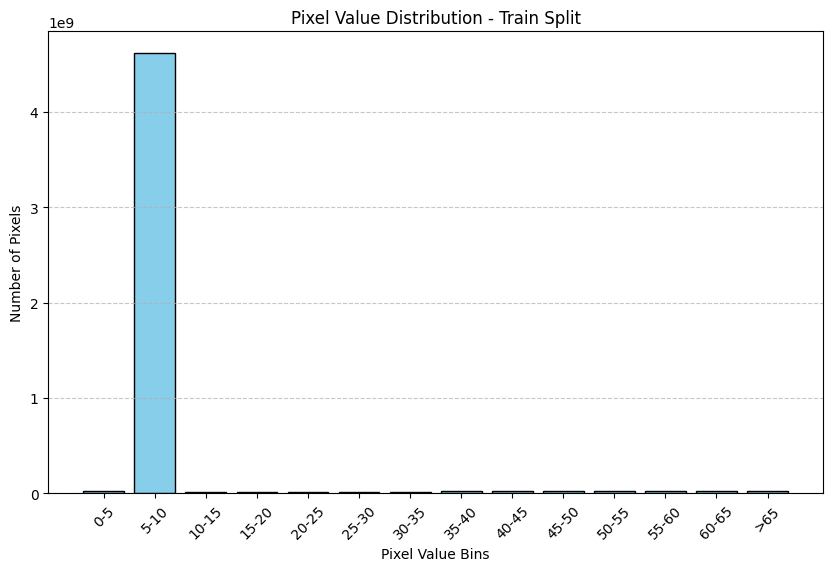

✅ Train Split Processed - Total Pixels: 34,523,840,512
  0-5: 24,580,232 pixels (0.07%)
  5-10: 4,613,384,589 pixels (13.36%)
  10-15: 11,410,914 pixels (0.03%)
  15-20: 12,473,881 pixels (0.04%)
  20-25: 13,860,214 pixels (0.04%)
  25-30: 15,991,718 pixels (0.05%)
  30-35: 18,613,858 pixels (0.05%)
  35-40: 20,538,817 pixels (0.06%)
  40-45: 21,970,438 pixels (0.06%)
  45-50: 23,118,459 pixels (0.07%)
  50-55: 23,632,453 pixels (0.07%)
  55-60: 24,093,798 pixels (0.07%)
  60-65: 24,655,423 pixels (0.07%)
  >65: 24,707,383 pixels (0.07%)

--------------------------------------------------



Processing val: 100%|██████████| 1175/1175 [03:27<00:00,  5.65file/s]
/tmp/ipykernel_408205/3549145240.py:55: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=45)


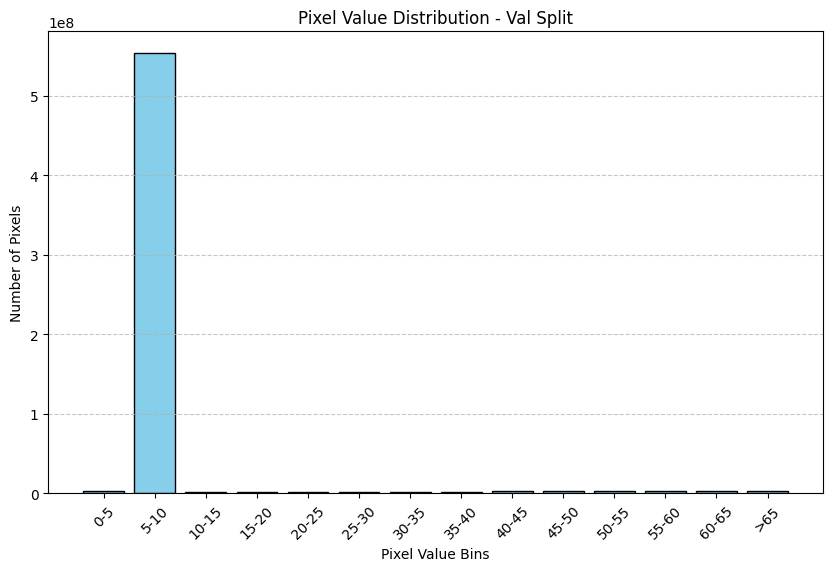

✅ Val Split Processed - Total Pixels: 4,312,268,800
  0-5: 2,900,913 pixels (0.07%)
  5-10: 552,983,598 pixels (12.82%)
  10-15: 1,339,721 pixels (0.03%)
  15-20: 1,669,743 pixels (0.04%)
  20-25: 2,091,157 pixels (0.05%)
  25-30: 2,326,553 pixels (0.05%)
  30-35: 2,306,337 pixels (0.05%)
  35-40: 2,257,483 pixels (0.05%)
  40-45: 2,498,510 pixels (0.06%)
  45-50: 2,701,455 pixels (0.06%)
  50-55: 2,542,925 pixels (0.06%)
  55-60: 2,707,896 pixels (0.06%)
  60-65: 2,631,063 pixels (0.06%)
  >65: 2,575,090 pixels (0.06%)

--------------------------------------------------



Processing fix_val: 100%|██████████| 1177/1177 [03:24<00:00,  5.76file/s]
/tmp/ipykernel_408205/3549145240.py:55: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels, rotation=45)


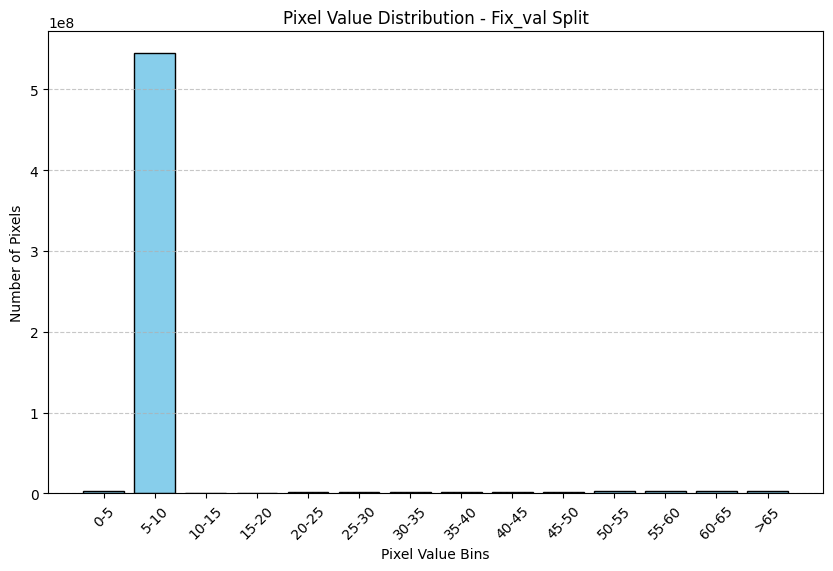

✅ Fix_val Split Processed - Total Pixels: 4,319,608,832
  0-5: 3,376,873 pixels (0.08%)
  5-10: 544,585,980 pixels (12.61%)
  10-15: 666,274 pixels (0.02%)
  15-20: 923,065 pixels (0.02%)
  20-25: 1,238,290 pixels (0.03%)
  25-30: 1,500,177 pixels (0.03%)
  30-35: 1,690,322 pixels (0.04%)
  35-40: 1,857,362 pixels (0.04%)
  40-45: 2,072,934 pixels (0.05%)
  45-50: 2,392,110 pixels (0.06%)
  50-55: 2,748,157 pixels (0.06%)
  55-60: 2,946,998 pixels (0.07%)
  60-65: 2,966,851 pixels (0.07%)
  >65: 2,917,174 pixels (0.07%)

--------------------------------------------------



In [5]:
# Dictionary to store bin counts for all splits
all_bin_counts = {}

# Process each dataset split
for split in splits:
    file_path = os.path.join(split_dir, f"{split}.csv")

    if not os.path.exists(file_path):
        print(f"❌ File not found: {file_path}")
        continue

    # Read CSV and extract paths
    data = pd.read_csv(file_path)

    if path_column not in data.columns:
        print(f"❌ Column '{path_column}' not found in {split}.csv")
        continue

    # Initialize bin counts
    bin_counts = np.zeros(len(bins) + 1, dtype=int)

    # Process each .npz file with a progress bar
    for npz_path in tqdm(data[path_column], desc=f"Processing {split}", unit="file"):
        image_path = os.path.join('/home/ubuntu/work/satellite_data/sentinel_pauls_paper/samples/', npz_path)
        if not os.path.exists(image_path):
            print(f"⚠️ Warning: File not found {image_path}")
            continue

        try:
            # Load .npz file
            with np.load(image_path) as npz:
                if array_key not in npz:
                    print(f"⚠️ Warning: Key '{array_key}' not found in {image_path}")
                    continue

                # Extract pixel values
                pixel_values = npz[array_key].flatten()

                # Bin values
                bin_indices = np.digitize(pixel_values, bins, right=False)
                bin_counts += np.bincount(bin_indices, minlength=len(bins) + 1)

        except Exception as e:
            print(f"⚠️ Error loading {image_path}: {e}")

    # Store results for later
    all_bin_counts[split] = bin_counts[:-1]  # Exclude out-of-bounds bin

    # Create histogram plot
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.bar(labels, bin_counts[:-1], color="skyblue", edgecolor="black")  # Exclude last bin (>65)
    ax.set_title(f"Pixel Value Distribution - {split.capitalize()} Split")
    ax.set_xlabel("Pixel Value Bins")
    ax.set_ylabel("Number of Pixels")
    ax.set_xticklabels(labels, rotation=45)
    ax.grid(axis="y", linestyle="--", alpha=0.7)

    # Assign to specific variable
    if split == "train":
        plt_train = fig
    elif split == "val":
        plt_val = fig
    elif split == "fix_val":
        plt_fixval = fig

    # Show the plot inline
    plt.show()

    # Print summary stats
    total_pixels = bin_counts.sum()
    print(f"✅ {split.capitalize()} Split Processed - Total Pixels: {total_pixels:,}")
    for label, count in zip(labels, bin_counts[:-1]):
        percentage = (count / total_pixels) * 100 if total_pixels > 0 else 0
        print(f"  {label}: {count:,} pixels ({percentage:.2f}%)")

    print("\n" + "-"*50 + "\n")


In [ ]:
# Save the plot
output_path = os.path.join(split_dir, f"{split}_histogram.png")
plt.savefig(output_path)
plt.show()

print(f"\n✅ Histogram for {split} split saved as {output_path}\n")

In [2]:
print(5 // 2)
print(5/2)

2
2.5


In [ ]:
# Process each dataset split
for split in splits:
    file_path = os.path.join(split_dir, f"{split}.csv")

    if not os.path.exists(file_path):
        print(f"❌ File not found: {file_path}")
        continue

    # Read the dataset split CSV
    data = pd.read_csv(file_path)

    if path_column not in data.columns:
        print(f"❌ Column '{path_column}' not found in {split}.csv")
        continue

    # Initialize bin counts
    bin_counts = np.zeros(len(bins) + 1, dtype=int)

    # Process each .npz file
    for npz_path in data[path_column]:
        if not os.path.exists(npz_path):
            print(f"⚠️ Warning: File not found {npz_path}")
            continue

        try:
            # Load .npz file
            with np.load(npz_path) as npz:
                if array_key not in npz:
                    print(f"⚠️ Warning: Key '{array_key}' not found in {npz_path}")
                    continue

                # Extract pixel values
                pixel_values = npz[array_key].flatten()  # Flatten to 1D array

                # Bin values
                bin_indices = np.digitize(pixel_values, bins, right=False)
                bin_counts += np.bincount(bin_indices, minlength=len(bins) + 1)

        except Exception as e:
            print(f"⚠️ Error loading {npz_path}: {e}")

    # Create histogram
    plt.figure(figsize=(10, 6))
    plt.bar(labels, bin_counts[:-1], color="skyblue", edgecolor="black")  # Exclude last bin (>65)
    plt.title(f"Pixel Value Distribution - {split.capitalize()} Split")
    plt.xlabel("Pixel Value Bins")
    plt.ylabel("Number of Pixels")
    plt.xticks(rotation=45)
    plt.grid(axis="y", linestyle="--", alpha=0.7)

    # Save the plot
    output_path = os.path.join(split_dir, f"{split}_histogram.png")
    plt.savefig(output_path)
    plt.show()

    print(f"\n✅ Histogram for {split} split saved as {output_path}\n")
